# Module 11b: Falling water levels in the Eastern Snake Plain Aquifer

*The code behind GEOS 212: Water in the West, Boise State University*

Under the Eastern Snake River Plain, from Ashton down to King Hill, lies one of the most productive aquifers in the country: the **Eastern Snake Plain Aquifer (ESPA)**. Water moves through cracks and rubbly layers between stacked basalt lava flows and comes back out at places like the Thousand Springs along the Snake River canyon. Farmers pump it to irrigate roughly a million acres, and towns from Idaho Falls to Twin Falls drink it.

The previous notebook (11) "weighed" the water over the whole region with the GRACE satellites. Satellites are blurry (about 300 km pixels). To see the aquifer itself, we go down a well with a tape measure. Hydrologists have done exactly that at some ESPA wells several times a year since the late 1940s.

The quantity they record is **depth to water**: how far below the land surface the water table sits, in feet. A *bigger* number means a *lower* water table.

**Where are we in the water year?** Underground, where the water year barely shows. The snowmelt that ran off the mountains in spring (Modules 04-06) partly soaks into the aquifer through canals, fields and river beds, and it can take months to decades to reach the springs.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order.

## 1. Setup

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

# The GEOS 212 "water" colors, so these plots match the lecture slides
INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

# If a live download fails (no internet, or an agency changes its website),
# we fall back to a copy of the data saved in this repository.
DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

def fetch_text(url, cache_name):
    """Download text from `url`. Save a copy as data/<cache_name>.
    If the download fails, use the saved copy instead."""
    try:
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        text = r.text
        if DATA_DIR.exists():
            (DATA_DIR / cache_name).write_text(text)
        print(f"Downloaded live data -> {cache_name}")
    except Exception as err:
        print(f"Live download failed ({type(err).__name__}); using saved copy of {cache_name}")
        local = DATA_DIR / cache_name
        text = local.read_text() if local.exists() else requests.get(DATA_URL + cache_name, timeout=60).text
    return text

## 2. Getting well measurements from USGS

The U.S. Geological Survey's **Water Data API** serves every field measurement of groundwater level it has. We ask for one well (`monitoring_location_id`) and one kind of measurement: parameter code **72019**, "depth to water level, feet below land surface." Asking for `f=csv` gets a plain table back.

We'll use four long-record wells spread across the plain, labeled A-D (the same wells as on the Module 11 slide).

In [2]:
WELLS = pd.DataFrame([
    # label, USGS site number,  longitude, latitude, local name
    ("A", "435339112444601", -112.7469, 43.8939, "USGS 25"),
    ("B", "434307112382601", -112.6414, 43.7187, "USGS 21"),
    ("C", "433520112572601", -112.9589, 43.5888, "MTR Test"),
    ("D", "432700112470801", -112.7865, 43.4499, "USGS 1"),
], columns=["label", "site", "lon", "lat", "name"]).set_index("label")

def get_usgs_well(site):
    """All depth-to-water measurements (feet below land surface) at a USGS well.
    Returns a pandas Series indexed by date, oldest first."""
    url = ("https://api.waterdata.usgs.gov/ogcapi/v0/collections/field-measurements/items"
           f"?f=csv&monitoring_location_id=USGS-{site}&parameter_code=72019"
           "&properties=time,value&skipGeometry=true&limit=10000")
    text = fetch_text(url, f"usgs_well_{site}.csv")
    df = pd.read_csv(io.StringIO(text))
    depth = pd.to_numeric(df["value"], errors="coerce")
    depth.index = pd.to_datetime(df["time"].str[:10])
    return depth.dropna().sort_index().rename("depth_ft")

depth = {lab: get_usgs_well(row.site) for lab, row in WELLS.iterrows()}
for lab, d in depth.items():
    print(f"Well {lab}: {len(d):5d} measurements, {d.index.min():%Y}-{d.index.max():%Y}, "
          f"depth {d.min():.0f}-{d.max():.0f} ft")

Downloaded live data -> usgs_well_435339112444601.csv


Downloaded live data -> usgs_well_434307112382601.csv


Downloaded live data -> usgs_well_433520112572601.csv


Downloaded live data -> usgs_well_432700112470801.csv
Well A:  3643 measurements, 1952-2026, depth 260-301 ft
Well B:  3612 measurements, 1952-2026, depth 325-351 ft
Well C:  2846 measurements, 1949-2026, depth 448-474 ft
Well D:  2101 measurements, 1949-2026, depth 582-598 ft


These wells are deep: the water table is hundreds of feet down in the basalt. Let's plot every measurement at well A. We flip the y-axis so that "down" on the plot means "deeper," like looking down the well.

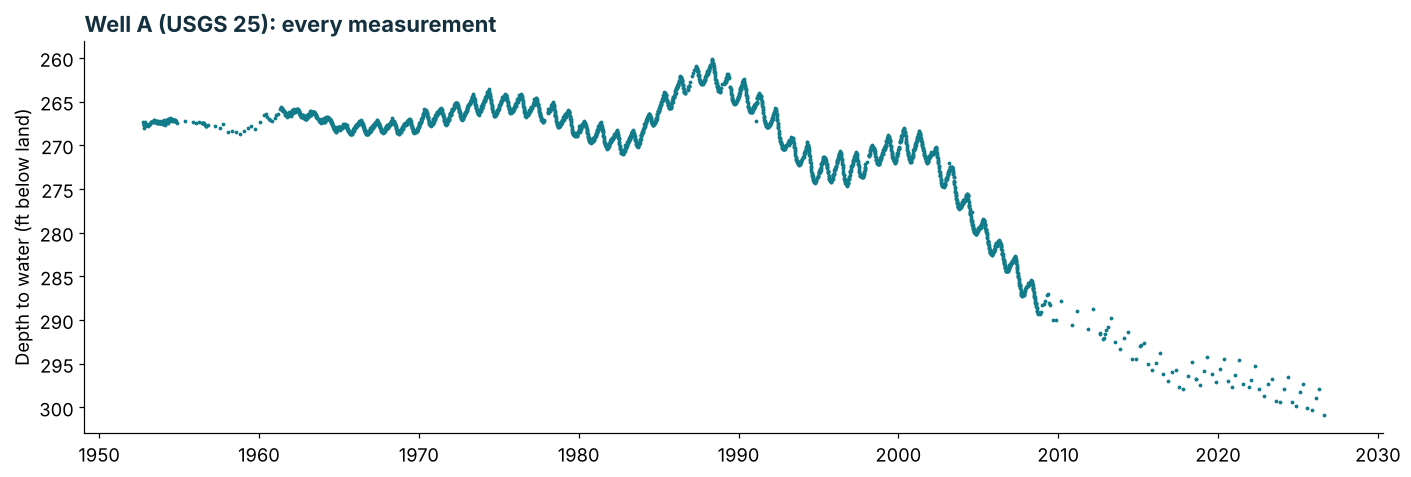

In [3]:
d = depth["A"]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(d.index, d, ".", ms=3, color=RIVER)
ax.invert_yaxis()
ax.set_ylabel("Depth to water (ft below land)")
ax.set_title(f"Well A ({WELLS.loc['A', 'name']}): every measurement", loc="left", fontweight="bold", color=INK)
plt.tight_layout()

Two things stand out. The record was steady (with wiggles) for about 50 years, and then the water table started dropping around 2000. Measurements also got much more frequent recently; some wells now have automatic sensors.

## 3. Annual means and a baseline

Some years have one measurement and some have hundreds, so let's average each year. Then we compare each year with a **baseline**, the average of 1955-1985, and flip the sign so that a negative change means the water table is *lower* (deeper) than it used to be.

2026 values are provisional (measurements through October 2026).


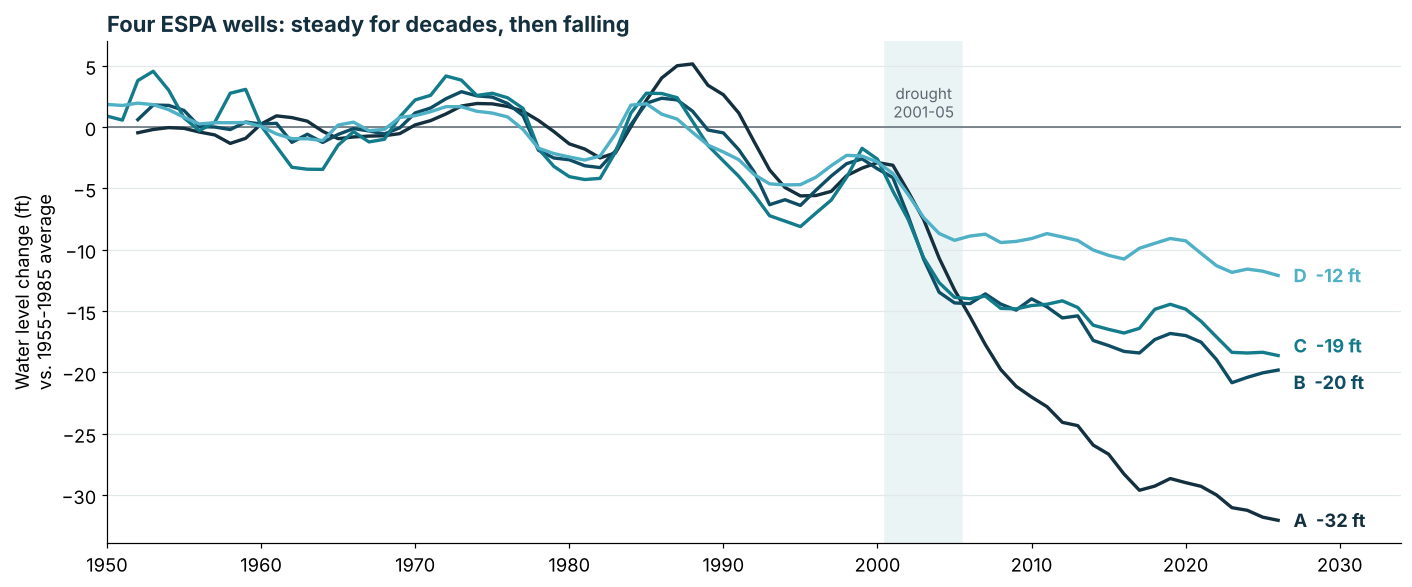

In [4]:
change = {}
for lab, d in depth.items():
    annual = d.groupby(d.index.year).mean()
    baseline = annual.loc[1955:1985].mean()
    change[lab] = baseline - annual          # negative = deeper than the 1955-1985 average

colors = {"A": INK, "B": DEEP, "C": RIVER, "D": GLACIER}
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.axhline(0, color=BASALT, lw=1)
ax.axvspan(2000.5, 2005.5, color=MIST, zorder=0)
ax.text(2003, 3.5, "drought\n2001-05", ha="center", va="top", fontsize=10, color=BASALT)
for lab, c in change.items():
    c = c.loc[1950:]
    ax.plot(c.index, c, color=colors[lab], lw=2.2)
    nudge = {"B": -1.0, "C": 0.8}.get(lab, 0)            # keep the B and C labels apart
    ax.text(c.index[-1] + 1, c.iloc[-1] + nudge, f"{lab}  {c.iloc[-1]:.0f} ft", va="center",
            fontsize=12, fontweight="bold", color=colors[lab])
ax.set_xlim(1950, 2034)
ax.set_ylabel("Water level change (ft)\nvs. 1955-1985 average")
ax.set_title("Four ESPA wells: steady for decades, then falling", loc="left", fontweight="bold", color=INK)
ax.grid(axis="y", color="#E3E8EA", lw=0.8)
plt.tight_layout()
print("2026 values are provisional (measurements through October 2026).")

## 4. How fast is it falling?

Fit a straight line to each well's annual changes since 2000 with `np.polyfit` (as in Lab 07). The slope is the rate of decline in feet per year.

In [5]:
for lab, c in change.items():
    recent = c.loc[2000:2025].dropna()
    slope, intercept = np.polyfit(recent.index, recent.values, 1)
    print(f"Well {lab}: {slope:+.2f} ft per year since 2000")

Well A: -1.15 ft per year since 2000
Well B: -0.51 ft per year since 2000
Well C: -0.40 ft per year since 2000
Well D: -0.23 ft per year since 2000


## 5. Many more wells: the Idaho Department of Water Resources

Four wells are a small sample. The **Idaho Department of Water Resources (IDWR)** measures hundreds of ESPA wells, usually each spring and fall, and serves them through a groundwater data portal built on software called KiWIS. Each well's record has a time-series id (`ts_id`).

We'll use 12 IDWR wells that were measured at least 3 times before 1990 and at least twice in 2022-2026. Since most IDWR records start in the late 1970s, we compare **the average before 1990** with **the average since 2022**. We'll do the same for the four USGS wells, plus one more long-record USGS well in the northeast part of the plain.

In [6]:
IDWR_WELLS = [  # ts_id, longitude, latitude
    ("126988010", -113.3895, 43.7763), ("126452010", -113.3953, 43.6299), ("127268010", -113.3288, 43.7433),
    ("126932010", -113.3861, 43.7855), ("126100010", -113.3654, 43.6670), ("126308010", -113.3220, 43.6385),
    ("127540010", -112.9559, 43.7975), ("128076010", -112.9944, 43.8424), ("127948010", -113.0540, 43.8455),
    ("197164010", -114.4169, 42.9692), ("197212010", -114.4136, 42.9547), ("187916010", -114.1105, 42.7785)]

import json

def get_idwr_well(ts_id):
    """Depth-to-water measurements (ft) for one IDWR well time series."""
    url = ("https://idwr-groundwater-data.idaho.gov/KiWIS/KiWIS?service=kisters&type=queryServices"
           f"&datasource=0&format=json&request=getTimeseriesValues&ts_id={ts_id}"
           "&from=1940-01-01&to=2026-11-01&returnfields=Timestamp,Value")
    rows = json.loads(fetch_text(url, f"idwr_well_{ts_id}.json"))[0]["data"]   # [[timestamp, value], ...]
    return pd.Series([r[1] for r in rows], index=pd.to_datetime([r[0][:10] for r in rows]),
                     dtype=float).sort_index()

def usgs_change(d):
    """1955-1985 baseline (mean of annual means) minus the 2022-2026 average depth."""
    annual = d.groupby(d.index.year).mean()
    return annual.loc[1955:1985].mean() - d[d.index.year >= 2022].mean()

def idwr_change(d):
    """Average depth before 1990 minus the 2022-2026 average depth."""
    return d[d.index.year < 1990].mean() - d[d.index.year >= 2022].mean()

rows = []
for lab, w in WELLS.iterrows():
    rows.append(("USGS", lab, w.lon, w.lat, usgs_change(depth[lab])))
rexburg = get_usgs_well("435504112222301")           # one more long USGS record, northeast part of the plain
rows.append(("USGS", "", -112.3736, 43.9180, usgs_change(rexburg)))
for ts_id, lon, lat in IDWR_WELLS:
    rows.append(("IDWR", "", lon, lat, idwr_change(get_idwr_well(ts_id))))

table = pd.DataFrame(rows, columns=["agency", "label", "lon", "lat", "change_ft"]).round({"change_ft": 1})
table

Downloaded live data -> usgs_well_435504112222301.csv


Downloaded live data -> idwr_well_126988010.json


Downloaded live data -> idwr_well_126452010.json


Downloaded live data -> idwr_well_127268010.json


Downloaded live data -> idwr_well_126932010.json


...

Downloaded live data -> idwr_well_127948010.json


Downloaded live data -> idwr_well_197164010.json


Downloaded live data -> idwr_well_197212010.json


Downloaded live data -> idwr_well_187916010.json


,agency,label,lon,lat,change_ft
0,USGS,A,-112.7469,43.8939,-31.2
1,USGS,B,-112.6414,43.7187,-20.1
2,USGS,C,-112.9589,43.5888,-18.1
3,USGS,D,-112.7865,43.4499,-11.7
4,USGS,,-112.3736,43.9180,-14.0
5,IDWR,,-113.3895,43.7763,-37.5
6,IDWR,,-113.3953,43.6299,-9.0
7,IDWR,,-113.3288,43.7433,-33.4
8,IDWR,,-113.3861,43.7855,-13.5
9,IDWR,,-113.3654,43.6670,-27.4


Every well is lower now than it was before 1990. Let's put them on a map. We don't need a fancy mapping package: longitude and latitude can go straight onto the x and y axes. We just set the aspect ratio so that a degree of longitude, which is shorter than a degree of latitude at 43° N, looks right.

Median drop across all 17 wells: 18 ft


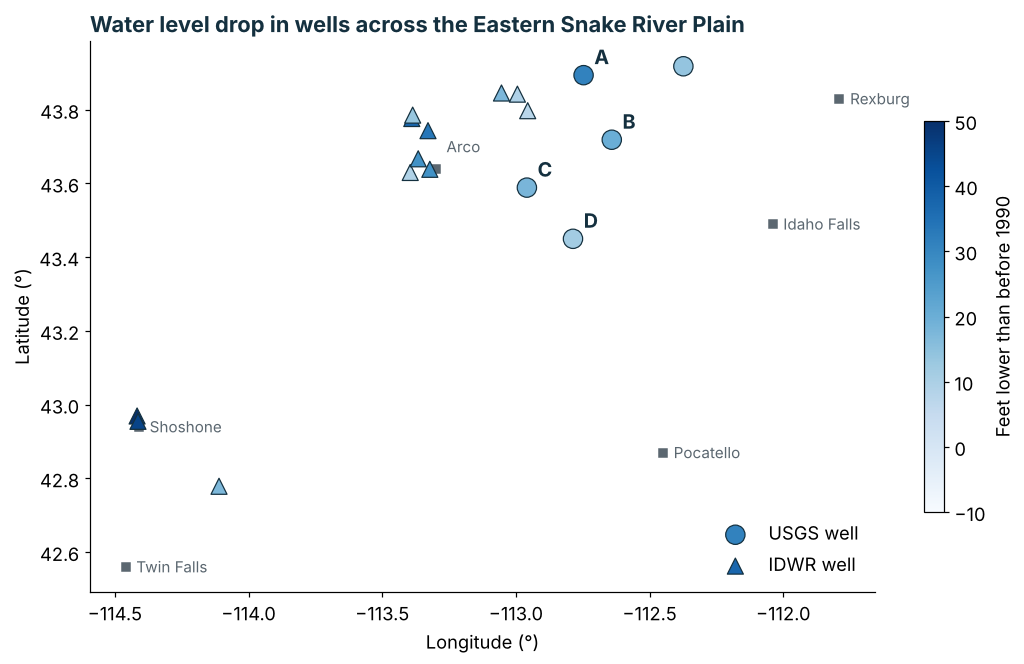

In [7]:
towns = {"Idaho Falls": (-112.04, 43.49), "Pocatello": (-112.45, 42.87), "Twin Falls": (-114.46, 42.56),
         "Arco": (-113.30, 43.64), "Rexburg": (-111.79, 43.83), "Shoshone": (-114.41, 42.94)}

fig, ax = plt.subplots(figsize=(10, 6))
drop = -table["change_ft"]                                   # positive = feet lower than before
for agency, marker, size in [("USGS", "o", 160), ("IDWR", "^", 110)]:
    t = table[table["agency"] == agency]
    sc = ax.scatter(t.lon, t.lat, c=drop[t.index], cmap="Blues", vmin=-10, vmax=50, marker=marker,
                    s=size, edgecolor=INK, lw=0.8, zorder=3, label=f"{agency} well")
for _, r in table[table["label"] != ""].iterrows():
    ax.text(r.lon + 0.04, r.lat + 0.03, r.label, fontsize=13, fontweight="bold", color=INK)
for name, (lon, lat) in towns.items():
    ax.plot(lon, lat, "s", ms=5, color=BASALT)
    ax.text(lon + 0.04, lat + (0.06 if name == "Arco" else 0), name, va="center", fontsize=10, color=BASALT)
ax.set_aspect(1 / np.cos(np.deg2rad(43.5)))
ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°)")
plt.colorbar(sc, ax=ax, shrink=0.7, label="Feet lower than before 1990")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Water level drop in wells across the Eastern Snake River Plain", loc="left", fontweight="bold", color=INK)
plt.tight_layout()
print(f"Median drop across all {len(table)} wells: {drop.median():.0f} ft")

## 6. Why are the water levels falling?

Water levels in an aquifer are a balance between water coming in (**recharge**) and water going out (**discharge**). For the ESPA:

- **In:** seepage from canals and flood-irrigated fields, leakage from the Snake River and its tributaries, and snowmelt soaking in, much of it from the mountains to the north (the Big Lost River, Little Lost River and Birch Creek sink into the plain near Arco).
- **Out:** springs along the Snake River (Thousand Springs), groundwater pumping, and seepage back into the river.

Three changes tipped the balance after about 2000:

1. **Drought.** 2001-2005 was a long dry spell, with little snowmelt to recharge the aquifer.
2. **More pumping.** Groundwater irrigation expanded from the 1950s through the 1980s.
3. **More efficient irrigation.** Farmers switched from flooding fields to sprinklers, and canals were lined. That saves water for the farm, but less water leaks through to the aquifer. Some of the "wasted" water in old flood irrigation was actually the aquifer's recharge.

Falling water levels mean less water coming out of the springs, and spring flows feed fish farms and senior surface-water rights downstream. That led to years of legal conflict between surface-water and groundwater users. Idaho's responses include an ESPA management plan (2009), a 2015 settlement in which groundwater pumpers agreed to cut their use, and **managed aquifer recharge**: in wet years, the state sends river water into canals and basins on purpose so it soaks into the aquifer.

Look again at the plot in section 3. Do you see any sign that the decline slows or reverses after the wet years of 2011, 2017 and 2023?

## 7. Your turn

1. **Seasons in a deep aquifer.** Pick the well with the most measurements since 2015 and plot each year's measurements by month. Is there a seasonal cycle? When in the year is the water table highest, and why might that be? (Think about canals and the irrigation season.)
2. **Rates.** Fit the trend in section 4 for 2000-2015 and for 2015-2025 separately. Is the decline slowing down? What could explain a change in the rate?
3. **Satellites vs. wells.** Notebook 11 found almost no trend in GRACE total water storage over the Snake River Plain. How can both be true? (Hints: how big is a GRACE pixel? How much water is a 20 ft water-table drop if the basalt's specific yield, the fraction of rock volume that drains, is about 0.05-0.1?)
4. **Find your own well.** Choose a well near where you live using the USGS Water Data for the Nation map. Change the site number in `get_usgs_well()` and plot it. Is the water level there rising or falling?

### Why code?
These wells were first measured by hand with a steel tape more than 70 years ago. Today you can pull every measurement from two agencies, compare 17 wells and fit trends in a few dozen lines. The hard part, and the valuable part, is the 70 years of patient measuring.

---
*Data: USGS field measurements of depth to water, parameter 72019 (Water Data API, api.waterdata.usgs.gov); Idaho Department of Water Resources groundwater data portal (KiWIS). 2026 values, through October 2026, are provisional.*